### Graph 3 : Sequential agents (Multiple Nodes)

In [6]:
from typing import TypedDict
from langgraph.graph import StateGraph

In [7]:
class AgentState(TypedDict):
    name : str
    age : int
    final : str

In [8]:
def first_node(state: AgentState)-> AgentState:
    state['final'] = f"Hi {state['name']} , Whats up"

    return state

def second_node(state:AgentState)-> AgentState:
    state['final'] = state['final'] + f" Your Age is {state['age']}"

    return state

In [9]:
graph = StateGraph(AgentState)

graph.add_node("first", first_node)
graph.add_node("second", second_node)

graph.set_entry_point("first")
graph.add_edge("first", "second")
graph.set_finish_point("second")

app = graph.compile()

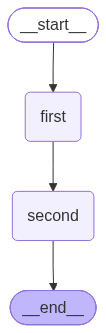

In [10]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [11]:
res= app.invoke({'name': "SAIF MUKADAM", 'age': 10})
res["final"]

'Hi SAIF MUKADAM , Whats up Your Age is 10'